# The Auction Room: analyst notebook

This notebook follows the game's chapters in Python. In the game, **Coder mode** shows these same steps.

You're the data analyst for an IPL franchise in a mega-auction year. You start from raw ball-by-ball data and finish with a retention decision, a squad plan and a war board of auction targets.

**Data:** put `ball_by_ball_data.csv` (IPL ball-by-ball, 2008–2026) in the `data/` folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

d = pd.read_csv("../data/ball_by_ball_data.csv")
d = d[~d.is_super_over & d.season_id.isin([2024, 2025, 2026])]    # the scouting window
print(f"{len(d):,} deliveries from {d.match_id.nunique()} matches")
d.head()

44,395 deliveries from 188 matches


,season_id,match_id,batter,bowler,non_striker,team_batting,team_bowling,over_number,ball_number,batter_runs,...,is_bye,is_penalty,wide_ball_runs,no_ball_runs,leg_bye_runs,bye_runs,penalty_runs,wicket_kind,is_super_over,innings
105596,2024,1422119,S Dube,AS Joseph,RA Jadeja,129,1,16,4,4,...,False,False,0,0,0,0,0,NaN,False,2
106094,2024,1422119,S Dube,AS Joseph,RA Jadeja,129,1,16,5,0,...,False,False,1,0,0,0,0,NaN,False,2
106138,2024,1422119,S Dube,AS Joseph,RA Jadeja,129,1,16,6,0,...,True,False,0,0,0,4,0,NaN,False,2
106275,2024,1422119,S Dube,AS Joseph,RA Jadeja,129,1,16,7,1,...,False,False,0,0,0,0,0,NaN,False,2
107180,2024,1422121,PD Salt,B Kumar,VR Iyer,6,2,2,2,0,...,False,False,0,0,0,0,0,NaN,False,1


## Chapter 1 · From deliveries to players

First, settle what each row means. A **wide** isn't a ball faced. A **run out** isn't the bowler's wicket. **Byes and leg byes** don't count against the bowler.

In [2]:
d["legal_bat"]  = ~d.is_wide_ball
d["legal_bowl"] = ~d.is_wide_ball & ~d.is_no_ball
d["conceded"]   = d.batter_runs + d.wide_ball_runs + d.no_ball_runs
d["bowler_wkt"] = d.is_wicket & d.wicket_kind.isin(
    ["caught", "bowled", "lbw", "caught and bowled", "stumped", "hit wicket"])

**Group by:** split the rows into one group per player, sum each column, and combine the results into a table.

In [3]:
bat = d.groupby("batter").agg(runs=("batter_runs", "sum"), balls=("legal_bat", "sum"))
outs = d[d.player_out.notna() & (d.wicket_kind != "retired hurt")].groupby("player_out").size()
bat["outs"] = outs.reindex(bat.index).fillna(0)

bowl = d.groupby("bowler").agg(balls_bowled=("legal_bowl", "sum"),
                               runs_conceded=("conceded", "sum"),
                               wickets=("bowler_wkt", "sum"))

bat["sr"]   = bat.runs / bat.balls * 100
bat["avg"]  = bat.runs / bat.outs.clip(lower=1)
bowl["eco"] = bowl.runs_conceded / (bowl.balls_bowled / 6)

bat[bat.balls >= 300].sort_values("sr", ascending=False).head(8).round(1)

,runs,balls,outs,sr,avg
batter,,,,,
Abhishek Sharma,1348,667,36.0,202.1,37.4
Priyansh Arya,828,412,25.0,201.0,33.1
PD Salt,1040,588,29.0,176.9,35.9
TH David,620,353,14.0,175.6,44.3
TM Head,1203,686,35.0,175.4,34.4
SP Narine,774,446,28.0,173.5,27.6
N Pooran,1105,648,28.0,170.5,39.5
RM Patidar,964,568,33.0,169.7,29.2


The game uses the cleaned player sheet built by `scripts/build_players.py` (active players, roles, overseas and keeper labels, and splits against spin and pace). Load it from here on:

In [4]:
df = pd.read_csv("../data/players.csv")
df["sr"]  = df.runs / df.balls * 100
df["avg"] = df.runs / df.outs.clip(lower=1)
df["eco"] = df.runs_conceded / (df.balls_bowled / 6)
df["wpm"] = df.wickets / df.matches
df["death_eco"] = df.death_runs / (df.death_balls / 6)
print(len(df), "players")
df.isna().sum()[["sr", "eco"]]   # missing ≠ zero: specialist bowlers' batting isn't scouted

154 players


sr     69
eco    72
dtype: int64

## Chapter 2 · Explore: sample size and shrinkage

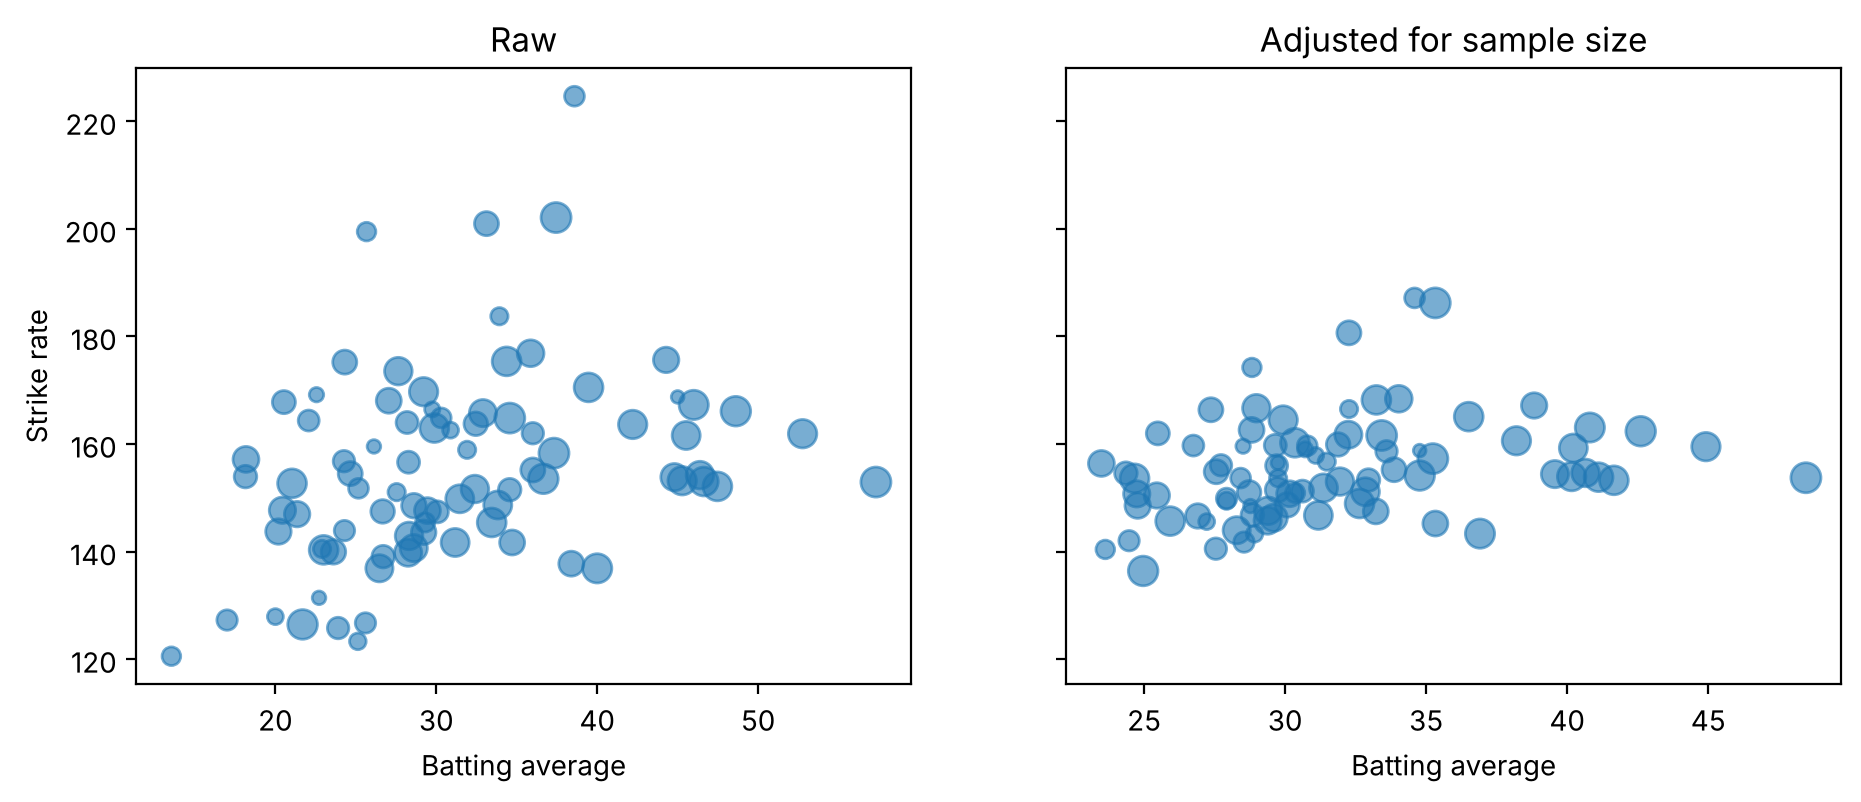

,name,team,matches,sr
5,AD Russell,KKR,25,175.2
10,Abhishek Sharma,SRH,39,202.1
36,H Klaasen,SRH,37,167.3
67,M Shahrukh Khan,GT,23,167.8
73,MP Stoinis,PBKS,32,165.7
82,N Pooran,LSG,36,170.5
86,Naman Dhir,MI,27,168.0
91,PD Salt,RCB,31,176.9
95,Priyansh Arya,PBKS,25,201.0
111,RM Patidar,RCB,35,169.7


In [5]:
K = 20
bats = df[df.balls >= 120].copy()
w = bats.matches / (bats.matches + K)
for col in ["sr", "avg"]:
    bats[col + "_adj"] = bats[col].mean() + (bats[col] - bats[col].mean()) * w

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].scatter(bats.avg, bats.sr, s=bats.matches * 3, alpha=.6); ax[0].set_title("Raw")
ax[1].scatter(bats.avg_adj, bats.sr_adj, s=bats.matches * 3, alpha=.6); ax[1].set_title("Adjusted for sample size")
for a in ax: a.set_xlabel("Batting average")
ax[0].set_ylabel("Strike rate"); plt.show()

bats[(bats.sr >= 165) & (bats.matches >= 20)][["name", "team", "matches", "sr"]].round(1)

## Chapter 3 · One ruler for every skill

A **z-score** counts how many standard deviations a value sits from the average.

*This is a simplified version of the game's model. The game also shrinks small samples, adds death-overs economy and experience, and caps values, so its numbers differ a little.*

In [6]:
def z(col):
    return (col - col.mean()) / col.std(ddof=0)

bats["z_sr"], bats["z_avg"] = z(bats.sr_adj), z(bats.avg_adj)
bowlers = df[df.balls_bowled.notna()].copy()
bowlers["z_eco"], bowlers["z_wpm"] = -z(bowlers.eco), z(bowlers.wpm)

r = bats.set_index("name").loc["AD Russell", "sr"]
n = bowlers.set_index("name").loc["SP Narine", "eco"]
print("Russell SR, steps from average:", round((r - bats.sr.mean()) / bats.sr.std(ddof=0), 2))
print("Narine economy, steps better:  ", round((bowlers.eco.mean() - n) / bowlers.eco.std(ddof=0), 2))

Russell SR, steps from average: 1.12
Narine economy, steps better:   2.43


In [7]:
W = dict(avg=1, sr=1, wpm=1, eco=1)
df["bat"]  = (W["avg"]*bats.z_avg + W["sr"]*bats.z_sr) / (W["avg"] + W["sr"])
df["bowl"] = (W["wpm"]*bowlers.z_wpm + W["eco"]*bowlers.z_eco) / (W["wpm"] + W["eco"])
both = df[["bat", "bowl"]]
df["impact"] = both.max(axis=1) + (0.4 * (both.min(axis=1) + 1).clip(lower=0)).where(both.notna().all(axis=1), 0)

a = 0.85 * 120 * 10 / np.exp(1.6 * df.impact).sum()        # all players ≈ 85% of the money in the room
df["market_cr"] = 32 * np.tanh(a * np.exp(1.6 * df.impact) / 32)
df.sort_values("market_cr", ascending=False)[["name", "team", "role", "impact", "market_cr"]].head(12).round(2)

,name,team,role,impact,market_cr
10,Abhishek Sharma,SRH,BAT,2.03,31.21
142,V Suryavanshi,RR,BAT,2.01,31.08
123,SP Narine,KKR,AR,1.89,30.13
139,V Kohli,RCB,BAT,1.57,24.94
48,JJ Bumrah,MI,BOWL,1.54,24.24
133,T Stubbs,DC,BAT,1.53,24.17
124,SS Iyer,PBKS,BAT,1.46,22.57
33,E Malinga,SRH,BOWL,1.44,22.04
95,Priyansh Arya,PBKS,BAT,1.43,21.95
52,JR Hazlewood,RCB,BOWL,1.41,21.48


## Chapter 5 · Retentions

Retention slabs are fixed: ₹18, 14, 11, 18 and 14 Cr. Keep a player only if he's worth more than his slab.

In [8]:
TEAM = "SRH"     # try any franchise code
slabs = [18, 14, 11, 18, 14]
sq = df[df.team == TEAM].sort_values("market_cr", ascending=False).head(8).copy()
sq["slab"] = (slabs + [np.nan] * 8)[:len(sq)]
sq["gain"] = sq.market_cr - sq.slab
sq[["name", "role", "market_cr", "slab", "gain"]].round(1)

,name,role,market_cr,slab,gain
10,Abhishek Sharma,BAT,31.2,18.0,13.2
33,E Malinga,BOWL,22.0,14.0,8.0
36,H Klaasen,WK,19.4,11.0,8.4
136,TM Head,BAT,10.3,18.0,-7.7
40,Harsh Dubey,BOWL,5.2,14.0,-8.8
92,PJ Cummins,BOWL,4.8,NaN,NaN
38,HV Patel,BOWL,4.6,NaN,NaN
47,JD Unadkat,BOWL,3.5,NaN,NaN


## Chapter 6 · Squad plan

Lay the squad out as a playing XI plus backups. Empty slots become the shopping list.

In [9]:
retained = sq[sq.gain > 0].head(5)
fits = {
    "Wicketkeeper": lambda p: p.role == "WK",
    "All-rounder":  lambda p: p.role == "AR",
    "Spinner":      lambda p: p.bowling_type == "S",
    "Pacer":        lambda p: p.bowling_type == "P",
    "Finisher":     lambda p: p.sr >= 160,
    "Batter":       lambda p: p.role in ("BAT", "WK", "AR"),
}
slots = ["Wicketkeeper", "All-rounder", "Spinner", "Spinner", "Pacer", "Pacer",
         "Finisher", "Batter", "Batter", "Batter", "Batter"]
plan, used = {}, set()
for i, s in enumerate(slots):
    pick = retained[[fits[s](p) and p.name not in used for p in retained.itertuples()]].head(1)
    plan[f"{i+1}. {s}"] = pick.name.iat[0] if len(pick) else None
    used.update(pick.name)
shopping = [s for s, p in plan.items() if p is None]
plan

{'1. Wicketkeeper': 'H Klaasen',
 '2. All-rounder': None,
 '3. Spinner': None,
 '4. Spinner': None,
 '5. Pacer': 'E Malinga',
 '6. Pacer': None,
 '7. Finisher': 'Abhishek Sharma',
 '8. Batter': None,
 '9. Batter': None,
 '10. Batter': None,
 '11. Batter': None}

## Chapter 7 · War board

Find auction players who fill a slot on the shopping list and are worth more to us than to the market.

In [10]:
purse = 120 - sum(slabs[:len(retained)])
pool = df[~df.name.isin(retained.name)].copy()
need_types = {s.split(". ")[1] for s in shopping}
pool["fills_slot"] = pool.apply(lambda p: any(fits[t](p) for t in need_types), axis=1)
pool["value_cr"] = pool.market_cr * np.where(pool.fills_slot, 1.35, 1.0)
targets = pool[pool.fills_slot].sort_values("value_cr", ascending=False).head(2 * len(shopping))
print(f"{TEAM}: ₹{purse} Cr for {15 - len(retained)} places")
targets[["name", "team", "role", "market_cr", "value_cr"]].round(1)

SRH: ₹77 Cr for 12 places


,name,team,role,market_cr,value_cr
142,V Suryavanshi,RR,BAT,31.1,42.0
123,SP Narine,KKR,AR,30.1,40.7
139,V Kohli,RCB,BAT,24.9,33.7
48,JJ Bumrah,MI,BOWL,24.2,32.7
133,T Stubbs,DC,BAT,24.2,32.6
124,SS Iyer,PBKS,BAT,22.6,30.5
95,Priyansh Arya,PBKS,BAT,21.9,29.6
52,JR Hazlewood,RCB,BOWL,21.5,29.0
66,M Prasidh Krishna,GT,BOWL,21.2,28.6
135,TH David,RCB,BAT,20.0,27.0


## What next?

- Add phase splits (powerplay, middle overs) next to death-overs economy.
- Back-test the price model against real auction prices.
- Model venues directly: this data has no venue column, so the game's ground profiles are assumptions. A venue-level dataset would let you measure them.